In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import warnings
warnings.filterwarnings('ignore') #ignoring some deprication warnings

**Step 1:**
-

In [ ]:
!pip install yellowbrick

In [ ]:
from yellowbrick.datasets import load_spam
from sklearn.model_selection import train_test_split

X, y = load_spam()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)

**Step 2: No data processing required**
-

**Step 3:**
-

In [ ]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=2000)
X_train_final, X_val, y_train_final, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=0)
model.fit(X_train_final, y_train_final)

LogisticRegression(max_iter=2000)

**Step 4-5:**
-

In [ ]:
pred = model.predict(X_val)

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_val, pred, target_names=['not spam', 'spam'], zero_division='warn'))

              precision    recall  f1-score   support

    not spam       0.94      0.93      0.94       507
        spam       0.90      0.90      0.90       321

    accuracy                           0.92       828
   macro avg       0.92      0.92      0.92       828
weighted avg       0.92      0.92      0.92       828



In [ ]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_val, pred)
cm

array([[474,  33],
       [ 32, 289]])

<Axes: >

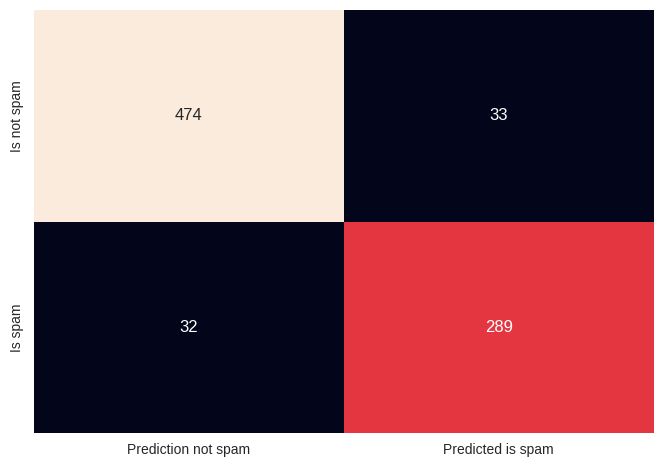

In [ ]:
#Better visualization
sns.heatmap(cm, fmt='d', annot=True, cbar=False, yticklabels=["Is not spam", "Is spam"], xticklabels=["Prediction not spam", "Predicted is spam"])

**We would want to increase recall**
-

In [ ]:
lower_threshold = model.decision_function(X_val) > -1
print(classification_report(y_val, lower_threshold, target_names=['not spam', 'spam'], zero_division='warn'))

              precision    recall  f1-score   support

    not spam       0.98      0.88      0.93       507
        spam       0.84      0.97      0.90       321

    accuracy                           0.92       828
   macro avg       0.91      0.93      0.91       828
weighted avg       0.92      0.92      0.92       828



In [ ]:
cm = confusion_matrix(y_val, lower_threshold)
cm

array([[448,  59],
       [ 10, 311]])

<Axes: >

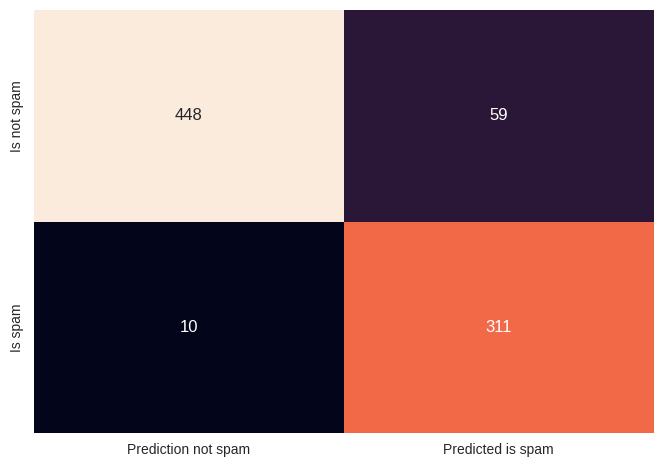

In [ ]:
sns.heatmap(cm, fmt='d', annot=True, cbar=False, yticklabels=["Is not spam", "Is spam"], xticklabels=["Prediction not spam", "Predicted is spam"])

**Questions**
-
---
1. We chose to decrease our threshold to improve our recall, as it is more important that we capture more actual postives (as in this case, it would capture more spam emails rather than letting them slip through). If we end up capturing normal emails, it is not as significant as letting spam emails slip through to the normal inbox, so increasing our precision was not as important as increasing our recall.

2. Our false negatives decreased to 10 and our false positives increased to 59. In this context, changing the decision boundary to catch more false negatives (more spam emails), we are unintentionally flagging more normal emails as spam. This means non-spam emails are being sent off to the spam inbox, but at least fewer spam emails are being flagged as safe.

3. We used the validation data when choosing the threshold as it was a part of the training data specifically set aside for helping choose our hyperparameters, to see which one will give us the best results for our data. Once we use the test data we cannot make more changes to the model without risking overfitting.

**Part 1B:**
-
---

**Step 3:**
-

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

lr=LogisticRegression(max_iter=2000)
svc=SVC()
RFC=RandomForestClassifier(random_state=0, max_depth=10)

lr.fit(X_train_final, y_train_final)
svc.fit(X_train_final, y_train_final)
RFC.fit(X_train_final, y_train_final)

RandomForestClassifier(max_depth=10, random_state=0)

**Step 4**
-

In [ ]:
from sklearn.model_selection import cross_validate

val_lr=cross_validate(lr, X_train_final, y_train_final, cv=5, return_train_score=True,scoring=('accuracy'))
val_svc=cross_validate(svc, X_train_final, y_train_final, cv=5, return_train_score=True,scoring=('accuracy') )
val_RFC=cross_validate(RFC, X_train_final, y_train_final, cv=5, return_train_score=True,scoring=('accuracy'))

print(val_lr)
print(val_svc)
print(val_RFC)

{'fit_time': array([5.98980546, 7.08183503, 3.84454918, 1.18734074, 1.1753757 ]), 'score_time': array([0.02690887, 0.00444913, 0.00388741, 0.00386047, 0.00389051]), 'test_score': array([0.90346908, 0.92911011, 0.93202417, 0.918429  , 0.91993958]), 'train_score': array([0.93204983, 0.92336731, 0.9245283 , 0.92415094, 0.93207547])}
{'fit_time': array([0.4532876 , 0.50218225, 0.5029099 , 0.3382709 , 0.34209681]), 'score_time': array([0.17292237, 0.18006873, 0.15538049, 0.09265161, 0.10106564]), 'test_score': array([0.69683258, 0.71342383, 0.70241692, 0.70694864, 0.72507553]), 'train_score': array([0.7217818 , 0.7206493 , 0.70603774, 0.7090566 , 0.71471698])}
{'fit_time': array([0.53805089, 0.53635716, 0.5354495 , 0.53552437, 0.53922844]), 'score_time': array([0.01472425, 0.01481557, 0.02278447, 0.01490283, 0.01461649]), 'test_score': array([0.93363499, 0.93815988, 0.94712991, 0.95166163, 0.92900302]), 'train_score': array([0.97130993, 0.96904492, 0.96981132, 0.97169811, 0.97056604])}


**Step 5.1**
-

In [ ]:
val_score_lr=val_lr.get('test_score').mean()
val_score_svc=val_svc.get('test_score').mean()
val_score_RFC=val_RFC.get('test_score').mean()

training_score_lr=val_lr.get('train_score').mean()
training_score_svc=val_svc.get('train_score').mean()
training_score_RFC=val_RFC.get('train_score').mean()

data={
    'Training Accuracy' : [training_score_lr, training_score_svc, training_score_RFC],
    'Validation Accuracy' : [val_score_lr, val_score_svc, val_score_RFC],

}
results = pd.DataFrame(data=data)
results

,Training Accuracy,Validation Accuracy
0,0.927234,0.920594
1,0.714448,0.708939
2,0.970486,0.939918


In [ ]:
print(X_val.describe().T[['min', 'max']])

                            min       max
word_freq_make              0.0     2.270
word_freq_address           0.0    14.280
word_freq_all               0.0     3.440
word_freq_3d                0.0    19.730
word_freq_our               0.0     6.250
word_freq_over              0.0     3.440
word_freq_remove            0.0     4.540
word_freq_internet          0.0     5.880
word_freq_order             0.0     1.810
word_freq_mail              0.0     4.340
word_freq_receive           0.0     2.000
word_freq_will              0.0     7.690
word_freq_people            0.0     5.550
word_freq_report            0.0     5.120
word_freq_addresses         0.0     2.310
word_freq_free              0.0    16.660
word_freq_business          0.0     4.870
word_freq_email             0.0     3.480
word_freq_you               0.0    18.750
word_freq_credit            0.0     4.760
word_freq_your              0.0     9.520
word_freq_font              0.0    17.100
word_freq_000               0.0   

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_final)

svc_scaled = SVC()
svc_scaled.fit(X_train_scaled, y_train_final)

val_svc_scaled = cross_validate(svc_scaled, X_train_scaled, y_train_final, cv=5, return_train_score=True,scoring=('accuracy') )

val_score_svc_scaled = val_svc_scaled.get('test_score').mean()
training_score_svc_scaled = val_svc_scaled.get('train_score').mean()

In [ ]:
print(f"Validation Score Scaled: {val_score_svc_scaled}")
print(f"Training Score Scaled: {training_score_svc_scaled}")

Validation Score Scaled: 0.928746474188095
Training Score Scaled: 0.9476902782822995


**Step 5.2**
-

In [ ]:
#RFC performed the best above - now using full training set and test set
full_RFC = RandomForestClassifier(random_state=0, max_depth=10)
full_RFC.fit(X_train, y_train)
RFC_pred = full_RFC.predict(X_test)

In [ ]:
print(classification_report(y_test, RFC_pred, target_names=['not spam', 'spam'], zero_division='warn'))

              precision    recall  f1-score   support

    not spam       0.95      0.98      0.96       263
        spam       0.97      0.93      0.95       197

    accuracy                           0.96       460
   macro avg       0.96      0.95      0.96       460
weighted avg       0.96      0.96      0.96       460



<Axes: >

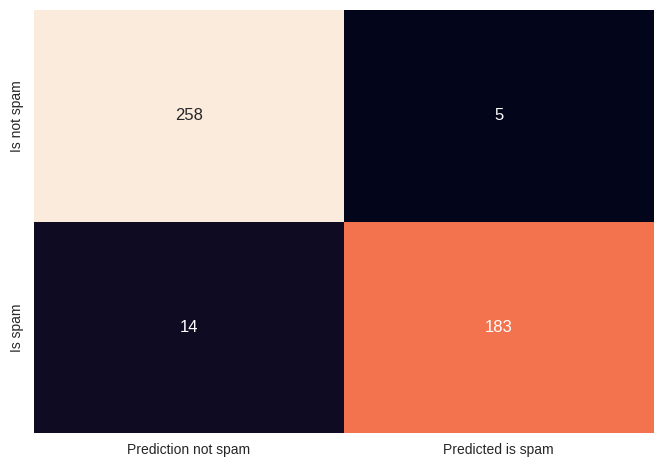

In [ ]:
cm = confusion_matrix(y_test, RFC_pred)
sns.heatmap(cm, fmt='d', annot=True, cbar=False, yticklabels=["Is not spam", "Is spam"], xticklabels=["Prediction not spam", "Predicted is spam"])

**Questions:**
-
---
1. We used the RandomForestClassifier as it had the highest overall validation and training scores when comparing it to logistic regression and both SVM models. It was close to the scaled SVC model we had, but was still slightly better.

2. Looking at the feature ranges, a tree-based model makes more sense for this dataset. Scaling the SVM did definitely improve both the accuracy and training scores. Its performance when scaled was nearly the same as the random forest, it was only slightly worse by about 0.02 for each score.

3. It overall depends on the results received. Changing the decision threshold is easier and less computationally expensive then trying multiple models. However, if the results you receive will not improve regardless of changing the decision threshold, then changing the model will help more. It also depends on how important it is if misclassifications are made via changes in the decision boundary, if this is something we do not want, then choosing a different model would be better.

**Part 2:**
-
---

**Step 1:**
-

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

auto_mpg = fetch_ucirepo(id=9)
X_reg = auto_mpg.data.features
y_reg = auto_mpg.data.targets

#with_car_name_preview = X_reg.join(auto_mpg.data.ids)
#with_car_name_preview.head()

X_reg.head()

print("Missing values in features:\n", X_reg.isnull().sum())

Missing values in features:
 displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
dtype: int64


**Step 2:**
-

In [ ]:
X_reg['horsepower'] = X_reg['horsepower'].fillna(X_reg['horsepower'].median())
print("\nMissing values in target:", y_reg.isnull().sum().sum())

X_numeric = X_reg.select_dtypes(include=[np.number])
print(f"\nShape of feature matrix X_numeric: {X_numeric.shape}")
print(f"Shape of target vector y_reg: {y_reg.shape}")


Missing values in target: 0

Shape of feature matrix X_numeric: (398, 7)
Shape of target vector y_reg: (398, 1)


**Step 3:**
-

In [ ]:
from sklearn.tree import DecisionTreeRegressor

X_train_tree, X_test_tree, y_train_tree, y_test_tree = train_test_split(X_numeric, y_reg, test_size=0.1, random_state=0)
depths = [3, 5, 7, 9, 11]

for depth in depths:
  tree = DecisionTreeRegressor(max_depth=depth, random_state=0)
  tree.fit(X_train_tree, y_train_tree)

  tree_cv = cross_validate(tree, X_train_tree, y_train_tree, cv=5, return_train_score=True, scoring='r2')
  print(f"For max_depth {depth}: Training Score = {tree_cv['train_score'].mean():.3f}, Validation Score = {tree_cv['test_score'].mean():.3f}")
  #Best results are from max_depth=9

For max_depth 3: Training Score = 0.828, Validation Score = 0.763
For max_depth 5: Training Score = 0.925, Validation Score = 0.758
For max_depth 7: Training Score = 0.968, Validation Score = 0.757
For max_depth 9: Training Score = 0.989, Validation Score = 0.791
For max_depth 11: Training Score = 0.997, Validation Score = 0.768


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor

forest = RandomForestRegressor(random_state=0)
gradient = GradientBoostingRegressor(random_state=0)
forest.fit(X_train_tree, y_train_tree)
gradient.fit(X_train_tree, y_train_tree)

forest_cv = cross_validate(forest, X_train_tree, y_train_tree, cv=5, return_train_score=True, scoring='r2')
gradient_cv = cross_validate(gradient, X_train_tree, y_train_tree, cv=5, return_train_score=True, scoring='r2')
print(f"Random Forest: Training Score = {forest_cv['train_score'].mean():.3f}, Validation Score = {forest_cv['test_score'].mean():.3f}")
print(f"Gradient Boosting: Training Score = {gradient_cv['train_score'].mean():.3f}, Validation Score = {gradient_cv['test_score'].mean():.3f}")
#RandomForest gives the best results overall

Random Forest: Training Score = 0.980, Validation Score = 0.866
Gradient Boosting: Training Score = 0.971, Validation Score = 0.860


**Step 4:**
-

In [ ]:
testing_accuracy = forest.score(X_test_tree, y_test_tree)
print(f"Testing Accuracy: {testing_accuracy:.3f}")

Testing Accuracy: 0.931
